# Support Vector Machines (Hard-Margin)

In [1]:
import numpy as np
import plotly.graph_objects as go

# Function to clip alpha values to the range [L, H]
def clipAlphasJ(aj, H, L):
       if aj > H:
               aj = H
       if L > aj:
               aj = L
       return aj

# Function to select a random index j different from i
def selectJrandom(i,m):
       j=i
       while (j==i):
            j = int(np.random.uniform(0,m))
       return j

# Simplified SMO algorithm for training a Support Vector Machine, which optimizes the Lagrange multipliers (alphas) to find the optimal hyperplane for classification.
def simplifiedSMO(dataX, classY):
    C = 1e10
    tol = 1e-3
    max_passes = 100
    X = np.asmatrix(dataX)
    Y = np.asmatrix(classY).T
    m, n = np.shape(X)
    b = 0
    alphas = np.asmatrix(np.zeros((m, 1)))
    passes = 0
    while (passes < max_passes):
        num_changed_alphas = 0
        for i in range(m):
            fXi = (np.multiply(alphas, Y).T * (X * X[i, :].T)).item() + b
            Ei = fXi - Y[i].item()
            if ((Y[i].item() * Ei < -tol) and (alphas[i].item() < C)) or ((Y[i].item() * Ei > tol) and (alphas[i].item() > 0)):
                j = selectJrandom(i, m)
                fXj = (np.multiply(alphas, Y).T * (X * X[j, :].T)).item() + b
                Ej = fXj - Y[j].item()
                alphaIold = alphas[i].copy()
                alphaJold = alphas[j].copy()
                if (Y[i].item() != Y[j].item()):
                    L = max(0, alphas[j].item() - alphas[i].item())
                    H = min(C, C + alphas[j].item() - alphas[i].item())
                else:
                    L = max(0, alphas[j].item() + alphas[i].item() - C)
                    H = min(C, alphas[j].item() + alphas[i].item())
                if L == H:
                    continue
                eta = 2.0 * X[i, :] * X[j, :].T - X[i, :] * X[i, :].T - X[j, :] * X[j, :].T
                if eta.item() >= 0:  # Also fix eta
                    continue
                alphas[j] -= Y[j].item() * (Ei - Ej) / eta.item()
                alphas[j] = clipAlphasJ(alphas[j].item(), H, L)  # clipAlphasJ expects scalar
                if (abs(alphas[j].item() - alphaJold.item()) < 0.00001):
                    continue
                alphas[i] += Y[j].item() * Y[i].item() * (alphaJold.item() - alphas[j].item())
                b1 = b - Ei - Y[i].item() * (alphas[i].item() - alphaIold.item()) * X[i, :] * X[i, :].T - Y[j].item() * (alphas[j].item() - alphaJold.item()) * X[i, :] * X[j, :].T
                b2 = b - Ej - Y[i].item() * (alphas[i].item() - alphaIold.item()) * X[i, :] * X[j, :].T - Y[j].item() * (alphas[j].item() - alphaJold.item()) * X[j, :] * X[j, :].T
                if (0 < alphas[i].item()) and (C > alphas[i].item()):
                    b = b1.item() if hasattr(b1, 'item') else b1
                elif (0 < alphas[j].item()) and (C > alphas[j].item()):
                    b = b2.item() if hasattr(b2, 'item') else b2
                else:
                    b = ((b1 + b2) / 2.0).item() if hasattr(b1, 'item') else (b1 + b2) / 2.0
                num_changed_alphas += 1
        if num_changed_alphas == 0:
            passes += 1
        else:
            passes = 0
    return alphas

In [2]:
# Summary:
# 1. Define the dataset
# 2. Compute alphas using simplified SMO algorithm (Lagrange multipliers) - with simplifiedSMO function
# 3. Compute w - the weight normal vector to the hyperplane
# 4. Compute margin width - the distance between the hyperplane and the closest samples is given by 2/||w||, where ||w|| is the Euclidean norm of the weight vector w.
# 5. Identify samples that are support vectors - those with alphas > 0
# 6. Compute b - the bias term 
# 7. Test new data points - The decision function for a sample x is defined as d(x)=w.T@x+b. The sign of the decision function value indicates the predicted class label for the sample, while the magnitude of the decision function value indicates how far the sample is from the hyperplane.

# Define the dataset
X = np.array([[-2,-1],[-1,-1],[0,0],[1,0],[2,0],[0,2],[3,2],[4,4]])
y = np.array([1,1,1,1,-1,-1,-1,-1])

# compute alphas using simplified SMO algorithm
alphas = simplifiedSMO(X,y)
print("Alphas=")
print(alphas)
print()

# Compute w - the weight normal vector to the hyperplane is given by 
# w = sum(alphas[i]*y[i]*X[i,:]) for i=1,...,m, where m is the number of samples in the dataset.
w = np.zeros((1,2))
for i in range(y.shape[0]):
    w = w + (alphas[i]*y[i]*X[i,:])
w = np.asmatrix(w).T

print(type(w))

print("w="+str(w))
print()

# Compute margin width - the distance between the hyperplane and the closest samples is given
# by 2/||w||, where ||w|| is the Euclidean norm of the weight vector w.
print("Margin width = " + str(2/np.linalg.norm(w)))
print()

# Identify samples that are support vectors - those with alphas > 0
ixSv = np.where(alphas>0)[0]

Svs = X[ixSv,:] # Support vectors are the samples in the dataset that correspond to the non-zero alphas.
ySvs = y[ixSv] # Class labels of the support vectors

# Identify the positive and negative support vectors
ixPosSvs = np.where(ySvs==1)[0] # Indexes of positive support vectors
ixNegSvs = np.where(ySvs==-1)[0] # Indexes of negative support vectors

PosSvs = Svs[ixPosSvs,:].T
NegSvs = Svs[ixNegSvs,:].T

print("Positive Support Vectors=")
print(PosSvs)
print()
print("Negative Support Vectors=")
print(NegSvs)
print()

# Compute b - the bias term is given by 
# b = -0.5*(w.T@PosSvs[:,0]+w.T@NegSvs[:,0]), 
# where PosSvs[:,0] and NegSvs[:,0] are the first positive and negative support vectors, respectively.
b = -0.5*(w.T@PosSvs[:,0]+w.T@NegSvs[:,0]).squeeze()

print("b="+str(b))
print()

Alphas=
[[0.        ]
 [0.        ]
 [0.        ]
 [3.99910964]
 [2.99925803]
 [0.99985161]
 [0.        ]
 [0.        ]]

<class 'numpy.matrix'>
w=[[-1.99940643]
 [-1.99970321]]

Margin width = 0.7072642091036614

Positive Support Vectors=
[[1]
 [0]]

Negative Support Vectors=
[[2 0]
 [0 2]]

b=[[2.99910964]]



In [3]:
xx = np.arange(np.min(X[:,0])-0.2,np.max(X[:,0])+0.2,0.1) # Range of x values for plotting the
                                                          # hyperplane and margin limits

hyperplane = -w[0]/w[1]*xx-b/w[1] # The hyperplane is defined by the equation w[0]*x1 + w[1]*x2 + b = 0,
                                  # which can be rearranged to x2 = -w[0]/w[1]*x1 - b/w[1]
negLine = -w[0]/w[1]*xx-b/w[1]-1/w[1] # The negative margin limit is defined by the equation w[0]*x1 + w[1]*x2 + b = -1
posLine = -w[0]/w[1]*xx-b/w[1]+1/w[1] # The positive margin limit is defined by the equation w[0]*x1 + w[1]*x2 + b = 1

hyperplane = np.array(hyperplane).squeeze() # Convert the hyperplane values to a 1D array for plotting
negLine = np.array(negLine).squeeze() # Convert the negative margin limit values to a 1D array for plotting
posLine = np.array(posLine).squeeze() # Convert the positive margin limit values to a 1D array for plotting

# Identify the indexes of the positive and negative samples for plotting
ixPos=np.where(y==1)[0]
ixNeg=np.where(y==-1)[0]

# Plot the data points, the hyperplane, the margin limits, and the support vectors
fig=go.Figure()
fig.add_trace(go.Scatter(x=X[ixPos,0],y=X[ixPos,1],name='w1'))
fig.add_trace(go.Scatter(x=X[ixNeg,0],y=X[ixNeg,1],name='w2'))
fig.update_traces(marker=dict(size=10))
fig.update_traces(mode='markers')

fig.add_trace(go.Scatter(x=xx,y=hyperplane,mode='lines', line=dict(color="black",width=4),name='Hyperplane'))
fig.add_trace(go.Scatter(x=xx,y=negLine,mode='lines', line=dict(color="red",width=3,dash='dash'),name='Negative margin limit'))
fig.add_trace(go.Scatter(x=xx,y=posLine,mode='lines', line=dict(color="blue",width=3,dash='dash'),name='Positive margin limit'))

fig.add_trace(go.Scatter(x=PosSvs[0,:],y=PosSvs[1,:],mode='markers',name='Pos. SV',
                         marker_size=15,marker_symbol="circle-open",marker=dict(color="blue",
                                                                                line=dict(width=3,color='blue'))))
fig.add_trace(go.Scatter(x=NegSvs[0,:],y=NegSvs[1,:],mode='markers',name='Neg. SV',
                         marker_size=15,marker_symbol="circle-open",marker=dict(color="red",
                                                                                line=dict(width=3,color='red'))))
fig.update_xaxes(title_text='f1')
fig.update_yaxes(title_text='f2')
fig.update_layout(
    autosize=False,
    width=900,
    height=800)

fig.show()

In [4]:
# Test on new data points 
# The decision function for a sample x is defined as d(x)=w.T@x+b. 
# The sign of the decision function value indicates the predicted class label for the sample, 
# while the magnitude of the decision function value indicates how far the sample is from the hyperplane.
# If the decision function value is greater than or equal to 0, then the sample is predicted to belong to class +1;
# if it is less than 0, then the sample is predicted to belong to class -1. 
# Additionally, if the decision function value is close to 1 or -1, then the sample is likely to be a support vector,
#  which means it is close to the margin and has a significant influence on the position of the hyperplane.

#Evaluate for sample x=[0.5,0.5].T
x=np.array([[0.5],[0.5]])
print("----------------Sample x="+str(x.T)+"-----------------")
dx = w.T@x+b #The decision function value for sample x
dx = np.array(dx).squeeze() #Convert the decision function value to a scalar
print("The decision function value is d(x)="+str(dx))
if(dx>=0): #If the decision function value is greater than or equal to 0, then sample x belongs to class +1
    print("Sample x="+str(x.T)+"T bellongs to class +1")
    if(dx>0.99 and dx<1.01):
        print("And it is a Support Vector!")
else: #If the decision function value is less than 0, then sample x belongs to class -1
    print("Sample x="+str(x.T)+"T bellongs to class -1")
    if(dx>-1.01 and dx<-0.99):
        print("And it is a Support Vector!")
    
#Evaluate for sample x=[1,1].T
x = np.array([[1],[1]])
print("----------------Sample x="+str(x.T)+"-----------------")
dx = w.T@x+b # The decision function value for sample x
dx = np.array(dx).squeeze() #Convert the decision function value to a scalar
print("The decision function value is d(x)="+str(dx))
if(dx>=0): # If the decision function value is greater than or equal to 0, then sample x belongs to class +1
    print("Sample x="+str(x.T)+"T bellongs to class +1")
    if(dx>0.99 and dx<1.01):
        print("And it is a Support Vector!")
else: # If the decision function value is less than 0, then sample x belongs to class -1
    print("Sample x="+str(x.T)+"T bellongs to class -1")
    if(dx>-1.01 and dx<-0.99):
        print("And it is a Support Vector!")

----------------Sample x=[[0.5 0.5]]-----------------
The decision function value is d(x)=0.9995548202148077
Sample x=[[0.5 0.5]]T bellongs to class +1
And it is a Support Vector!
----------------Sample x=[[1 1]]-----------------
The decision function value is d(x)=-1.0
Sample x=[[1 1]]T bellongs to class -1
And it is a Support Vector!


# Support Vector Machines (Soft-Margin & Non-Linear)

Apply SVM to the Cork Stoppers Data Set (Figure 2) in order to discriminate between classes Super and Average, and by considering the features N (Total number of defects) and PRT/10 (Total perimeter of the defects (in pixels) normalized by 10).

• Define the training and test datasets (consider 50% of the patterns for each one)

• Consider a linear kernel by considering diferent C values (e.g., [2^-20,...,2^15]). Determine the value of C that lead to the reduced error in testing. To decide about this you should run at least 10 times the algorithm involving di erent random selections of the training and testing data.

In [ ]:
import os
import numpy as np
import plotly.express as px
import pandas as pd
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn import svm
    
datasets_folder = os.path.abspath(os.path.join(os.getcwd() ,"../..")) + "/Datasets/" #Set the path to the datasets folder, which is assumed to be two levels up from the current working directory and then inside a "Datasets" folder. Adjust this path as necessary based on your actual directory structure.

Labels=["Super","Average","Poor"]        
xlsFile=pd.read_excel(datasets_folder + "CORK_STOPPERS.XLS",
                      sheet_name="Data",
                      usecols=["C","ART","N.1","PRT","ARM","PRM","ARTG","NG","PRTG","RAAR","RAN"])
CorkStopp=pd.DataFrame(data=xlsFile.dropna())

fnames = CorkStopp.columns[1:]

# Define the indexes for the different classes of cork stoppers based on the 'C' column
ixSuper = np.where(CorkStopp['C']==1)[0]
ixAverage = np.where(CorkStopp['C']==2)[0]
ixPoor = np.where(CorkStopp['C']==3)[0]
ixSupAvg = np.concatenate((ixSuper,ixAverage))

# Prepare the feature matrix X and the target vector y for training the SVM model
X = np.concatenate((np.array([CorkStopp['N.1'].to_numpy()[ixSupAvg]]).T,
                  np.array([CorkStopp['PRT'].to_numpy()[ixSupAvg]/10]).T),axis=1) # Data/Features
y = (CorkStopp['C'].to_numpy()[ixSupAvg]-1.5)*-2 # Labels

# Grid search for best C parameter in SVM

# The C parameter in SVM controls the trade-off between maximizing the margin and minimizing the classification error
# A smaller C value allows for a wider margin but may result in more misclassifications,
# while a larger C value aims to classify all training examples correctly but may lead to a narrower margin and potential overfitting.
# The grid search involves evaluating the performance of the SVM model for different values of C and selecting the one that yields the best results
# based on a chosen evaluation metric, such as accuracy or error rate.

runs = np.arange(0,10) # Define the number of runs for creating different training/testing partitions of the dataset
CsP2 = np.arange(-20.0,20.0,2.0) # Define a range of C values to evaluate, where CsP2 represents the powers of 2 for the C parameter in the SVM

errMat = np.zeros((runs.shape[0],CsP2.shape[0]))

# Create several training/testing partitions and evaluate the error for different values of C
for r in runs:#
    X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.5, test_size=0.5, random_state=r) # Split the dataset into training and testing sets, with a 50% split and using the current random seed r for reproducibility.
    ki = 0 # Index for the C parameter
    for cP2 in CsP2:#Evaluate different Cs
        #fit SVM
        clf = svm.SVC(kernel="linear", C=2**cP2)
        clf.fit(X_train, y_train)
        yp = clf.predict(X_test)
        #Evaluate error
        Hits=(np.where(yp==y_test)[0]).shape[0] 
        Acc = Hits/y_test.shape[0]

        #Store error
        errMat[r,ki]=(1-Acc)*100
        
        ki = ki+1
        
#at the end compute average error and error standard deviation
avgError=np.mean(errMat,axis=0)
stdError=np.std(errMat,axis=0)
xTickTexts=[]
for cP2 in CsP2:
    xTickTexts.append("2^"+str(int(cP2)))

#Display average error as function of power of C
fig = px.scatter(x=CsP2, y=avgError,error_y=stdError)
fig.update_layout(
    xaxis=dict(
        title=dict(text="C"),
        tickmode = 'array',
        tickvals = CsP2,
        ticktext = xTickTexts
    ),
    yaxis=dict(
        title=dict(
            text="Average Erros±Std"
        )
    ),
    font=dict(
        family="Courier New, monospace",
        size=18,
        color="RebeccaPurple"
    )
)
fig.show()

#Fing the best C
optC = CsP2[np.where(avgError==np.min(avgError))[0]][0]
print("Best C=2^"+str(optC))

# Train again SVM with best C
clf = svm.SVC(kernel = "linear", C = 2**optC)
clf.fit(X_train, y_train)

yp = clf.predict(X_test) #Predict the class labels for the test set using the trained SVM model with the best C value found in the previous step. The predicted class labels are stored in the variable yp.

# Model evaluation 
Hits = (np.where(yp==y_test)[0]).shape[0]

Acc = Hits/y_test.shape[0]

Err = (1-Acc)*100

print("Error (%)="+str(Err))


Best C=2^-8.0
Error (%)=7.9999999999999964


Plot data, and SVs.

In [6]:
# Plot the data points, the hyperplane, the margin limits, and the support vectors
svs = clf.support_vectors_ # The support vectors are the samples in the training set that correspond to the non-zero alphas, which are the samples that lie on the margin or within the margin and have a significant influence on the position of the hyperplane. The support vectors can be accessed using the support_vectors_ attribute of the trained SVM model.
ixNegSv = np.where(y_train[clf.support_]==-1)[0] # The indexes of the negative support vectors are obtained by checking which support vectors correspond to samples in the training set that have a class label of -1.
ixPosSv = np.where(y_train[clf.support_]==1)[0] # The indexes of the positive support vectors are obtained by checking which support vectors correspond to samples in the training set that have a class label of 1.
posSv = svs[ixPosSv,:] # Positive suport vectors
negSv = svs[ixNegSv,:] # Negative support vectors

# Decision hyperplane and margin limits
# The hyperplane is defined by the equation w[0]*x1 + w[1]*x2 + b = 0, which can be rearranged to x2 = -w[0]/w[1]*x1 - b/w[1]
xx = np.arange(np.min(X[:,0])-0.2,np.max(X[:,0])+0.2,0.1)
W = clf.coef_[0].squeeze() # The weight vector w can be accessed using the coef_ attribute of the trained SVM model. Since we are using a linear kernel, the weight vector is a 1D array with two elements corresponding to the coefficients for the two features in the dataset.
b = clf.intercept_[0] # The bias term b can be accessed using the intercept_ attribute of the trained SVM model. Since we are using a linear kernel, the bias term is a scalar value.
hyp = -W[0]/W[1]*xx-b/W[1] 
posLine = -W[0]/W[1]*xx-b/W[1]-1/W[1]
negLine = -W[0]/W[1]*xx-b/W[1]+1/W[1]

ixPos=np.where(y_train==1)[0]
ixNeg=np.where(y_train==-1)[0]

fig=go.Figure()
fig.add_trace(go.Scatter(x=X_train[ixPos,0],y=X_train[ixPos,1],name='Super'))
fig.add_trace(go.Scatter(x=X_train[ixNeg,0],y=X_train[ixNeg,1],name='Average'))
fig.update_traces(marker=dict(size=10))
fig.update_traces(mode='markers')

fig.add_trace(go.Scatter(x=xx,y=hyp,mode='lines', line=dict(color="black",width=4),name='Hyperplane'))
fig.add_trace(go.Scatter(x=xx,y=negLine,mode='lines', line=dict(color="blue",width=3,dash='dash'),name='Negative margin limit'))
fig.add_trace(go.Scatter(x=xx,y=posLine,mode='lines', line=dict(color="red",width=3,dash='dash'),name='Positive margin limit'))

fig.add_trace(go.Scatter(x=posSv[:,0],y=posSv[:,1],mode='markers',name='Pos. SV',
                         marker_size=15,marker_symbol="circle-open",marker=dict(color="blue",
                                                                                line=dict(width=3,color='blue'))))
fig.add_trace(go.Scatter(x=negSv[:,0],y=negSv[:,1],mode='markers',name='Neg. SV',
                         marker_size=15,marker_symbol="circle-open",marker=dict(color="red",
                                                                                line=dict(width=3,color='red'))))

fig.update_xaxes(title_text='N')
fig.update_yaxes(title_text='PRT/10')
fig.update_layout(
    autosize=False,
    width=900,
    height=800)

fig.show()

Plot classifier ROC and compute AUC.

In [7]:
from sklearn.metrics import roc_curve, auc

dx = W.T@X_test.T+b

ixPos=np.where(y_test==1)[0]
ixNeg=np.where(y_test==-1)[0]

print(ixNeg)

# Plot the decision function values for the test samples, highlighting the true positives and true negatives. The decision function values indicate how far the samples are from the hyperplane, with positive values indicating samples predicted to belong to class +1 and negative values indicating samples predicted to belong to class -1. The true positives are highlighted in red, while the true negatives are highlighted in black.
fig=go.Figure()
fig.add_scatter(x=np.arange(dx.shape[0]),y=dx,mode='lines+markers',name="d(x)")
fig.add_scatter(x=ixPos,y=dx[ixPos],mode='markers',marker_size=15,
                marker_symbol="circle-open",marker=dict(color="red"),line=dict(width=3,color='red'),name="True Positives")
fig.add_scatter(x=ixNeg,y=dx[ixNeg],mode='markers',marker_size=15,
                marker_symbol="circle-open",marker=dict(color="black"),line=dict(width=3,color='red'),name="True Negatives")
fig.update_layout(autosize=False,width=1200,height=500,title=dict(text="d(x)"))
fig.update_xaxes(title_text="Samples")
fig.update_yaxes(title_text="d(x)")
fig.show()

#ROC
fpr, tpr, _= roc_curve(y_test,dx,pos_label=1)
figR = go.Figure()
figR.add_scatter(x=fpr, y=tpr,mode='lines+markers')
figR.update_layout(autosize=False,width=700,height=700,title=dict(text="SVM ROC"))
figR.update_xaxes(title_text="1-SP",range=[-0.01, 1.01])
figR.update_yaxes(title_text="SS",range=[-0.01, 1.01])
    
#Area under de curve for Euclidean MDC
roc_auc = auc(fpr, tpr)
figR.add_annotation(x=0.5, y=0.5,
            text="AUC: "+str(roc_auc),
            showarrow=False,
            yshift=10)
figR.show()





[ 0  3  8  9 14 15 20 23 26 27 28 29 30 33 34 41 44 45 47 48]


• Make experiments with rbf kernel; perform a grid search with Gamma $\in$ [2^-25,2^-9,..., 2^-1,2^0] and C $\in$ [2^-10,2^-9,..., 2^24,2^25]. Determine the best value of C and Gamma that results in the reduced testing error. In the same way run at least 10 times the algorithm involving diferent random selections of the training and testing data. Plot the average error map for the di erent values of C and Gamma. Plot the ROC curve and the decision boundaries for the best SVMs, i.e. one with small error, and with the identified best C and Gamma values.

In [ ]:
# Grid search for best C and Gamma parameters in SVM with RBF kernel

runs = np.arange(0,10) #Create several training/testing partitions
CsP2 = np.arange(-10.0,25.0,1.0) #Define a range of C values to evaluate, where CsP2 represents the powers of 2 for the C parameter in the SVM
GsP2 = np.arange(-25.0,0.0,1.0) #Define a range of Gamma values to evaluate, where GsP2 represents the powers of 2 for the Gamma parameter in the SVM with RBF kernel. The Gamma parameter controls the influence of individual training samples on the decision boundary, with smaller values leading to a smoother decision boundary and larger values allowing for more complex decision boundaries that can capture intricate patterns in the data.

errMat = np.zeros((CsP2.shape[0],GsP2.shape[0],runs.shape[0])) # Initialize a 3D matrix to store the error values for each combination of C and Gamma parameters across different runs. The dimensions of the errMat matrix correspond to the number of C values, the number of Gamma values, and the number of runs, respectively. Each element in the errMat matrix will store the error percentage for a specific combination of C and Gamma parameters for a particular run.

# Grid search for best C and Gamma parameters in SVM with RBF kernel
for r in runs: #Create several training/testing partitions
    X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.5, test_size=0.5, random_state=r)
    ki = 0 # Index for the C parameter
    for cP2 in CsP2:#Evaluate different Cs
        ui = 0 # Index for the Gamma parameter
        for gP2 in GsP2:#Evaluate different Gammas
            #fit SVM
            clf = svm.SVC(kernel="rbf", C=2**cP2,gamma=2**gP2) #The SVM model is trained using the SVC class from the sklearn library, with the kernel parameter set to "rbf" to specify the use of the Radial Basis Function kernel, and the C and gamma parameters set to 2 raised to the power of cP2 and gP2, respectively, to evaluate different combinations of these hyperparameters during the grid search.
            clf.fit(X_train, y_train)
            yp = clf.predict(X_test)
            # Evaluate error
            Hits = (np.where(yp==y_test)[0]).shape[0]
            Acc = Hits/y_test.shape[0]

            #Store error
            errMat[ki,ui,r] = (1-Acc)*100
            ui = ui + 1
        ki = ki + 1

#at the end compute average error
avgError = np.mean(errMat,axis=2) #The average error is computed by taking the mean of the error values across all runs for each combination of C and Gamma parameters.
                                  #The resulting avgError matrix will have dimensions corresponding to the number of C values and the number of Gamma values evaluated in the grid search, with each element representing the average error for that specific combination of hyperparameters.
minErrorIx = np.where(avgError==avgError.min()) #Find the indexes of the minimum average error in the avgError matrix, which corresponds to the best combination of C and Gamma parameters found in the grid search. The minErrorIx variable will contain the row and column indexes of the minimum average error, which can be used to identify the corresponding C and Gamma values from the CsP2 and GsP2 arrays, respectively.

#Plot Error 
yTickTexts=[]
for cP2 in CsP2:
    yTickTexts.append("2^"+str(int(cP2)))
    
xTickTexts=[]
for gP2 in GsP2:
    xTickTexts.append("2^"+str(int(gP2)))


# Display average error as function of power of C and Gamma using a heatmap, where the x-axis represents the power of Gamma, the y-axis represents the power of C, and the color intensity represents the average error. The point corresponding to the minimum average error is highlighted with a marker to indicate the best combination of C and Gamma parameters found in the grid search.
fig=go.Figure()                             

fig.add_trace(go.Heatmap(
        z=avgError,
        x=GsP2,
        y=CsP2,
        colorscale='Viridis'))

fig.add_scatter(x=GsP2[minErrorIx[1]],y=CsP2[minErrorIx[0]],mode='markers',marker_size=15,
                marker_symbol="x",marker=dict(color="white"),line=dict(width=8,color='white'),name="Minimum error")
#fig.add_trace(go.Surface(x=Xp,y=Yp,z=Z2))
#fig.update_traces(contours_z=dict(show=True, usecolormap=True,highlightcolor="limegreen", project_z=True))

#fig.update_xaxes(title_text="Gamma")
#fig.update_yaxes(title_text="C")


fig.update_layout(
    xaxis=dict(
        title=dict(text="Gamma"),
        tickmode = 'array',
        tickvals = GsP2,
        ticktext = xTickTexts
    ),
    yaxis=dict(
        title=dict(text="C"),
        tickmode = 'array',
        tickvals = CsP2,
        ticktext = yTickTexts),
    font=dict(
        family="Courier New, monospace",
        size=18,
        color="RebeccaPurple"
    ),
    autosize=False,
    width=900,
    height=800)


fig.show()


print("One Best C=")
print("2^"+str(int(CsP2[minErrorIx[0]][0])))

print("One Best Gamma=")
print("2^"+str(int(GsP2[minErrorIx[1]][0])))

One Best C=
2^7
One Best Gamma=
2^-15


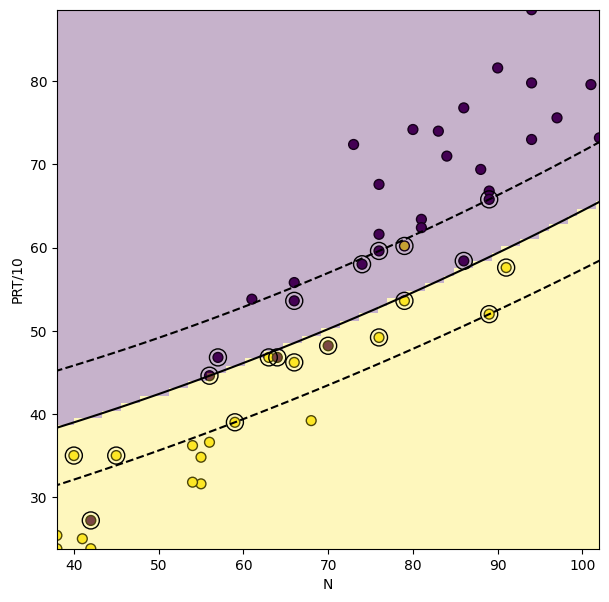

In [ ]:
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt


bestCP2=CsP2[minErrorIx[0]][0]
bestGP2=GsP2[minErrorIx[1]][0]
clf = svm.SVC(kernel="rbf", C=2**bestCP2,gamma=2**bestGP2)
clf.fit(X_train, y_train)

# Plotting settings
fig, ax = plt.subplots(figsize=(7, 7))
x_min, x_max, y_min, y_max = np.min(X_train[:,0]),np.max(X_train[:,0]),np.min(X_train[:,1]),np.max(X_train[:,1])
ax.set(xlim=(x_min, x_max), ylim=(y_min, y_max))

# Plot samples by color and add legend
scatter = ax.scatter(X_train[:, 0], X_train[:, 1], s=50, c=y_train, label=y_train, edgecolors="k")
plt.xlabel("N")
plt.ylabel("PRT/10")

# Plot decision boundary and margins
common_params = {"estimator": clf, "X": X, "ax": ax}
DecisionBoundaryDisplay.from_estimator(
    **common_params,
    response_method="predict",
    plot_method="pcolormesh",
    alpha=0.3,
)
DecisionBoundaryDisplay.from_estimator(
    **common_params,
    response_method="decision_function",
    plot_method="contour",
    levels=[-1, 0, 1],
    colors=["k", "k", "k"],
    linestyles=["--", "-", "--"],
)

# Plot bigger circles around samples that serve as support vectors
ax.scatter(
    clf.support_vectors_[:, 0],
    clf.support_vectors_[:, 1],
    s=150,
    facecolors="none",
    edgecolors="k",
    )

_ = plt.show()

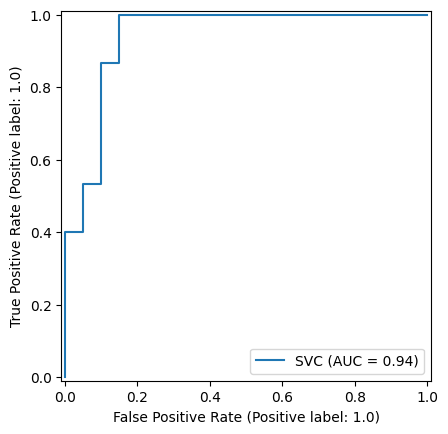

In [10]:
from sklearn.metrics import RocCurveDisplay

# Plot the ROC curve for the SVM model using the RocCurveDisplay class from the sklearn library
svc_disp = RocCurveDisplay.from_estimator(clf, X_test, y_test)
plt.show()


• Perform the SVM classification for discriminating the three classes w1,w2 and w3 of above problem. Consider an OAO strategy. In the same way as for the previous exercise perform a search for the best C and Gamma values. Evaluate the prediction error.

In [11]:
from sklearn.multiclass import OneVsOneClassifier

# Grid search for best C and Gamma parameters in SVM with RBF kernel for multi-class classification using One-vs-One strategy, which involves training a separate binary SVM classifier for each pair of classes in the dataset. The grid search evaluates different combinations of C and Gamma parameters for each binary classifier and selects the best combination based on the average error across all classifiers.
runs = np.arange(0,10)
CsP2 = np.arange(-10,25.0,1.0)
GsP2 = np.arange(-25.0,0.0,1.0)

errMat = np.zeros((CsP2.shape[0],GsP2.shape[0],runs.shape[0]))

# Create dataset and labels
X = np.concatenate((np.array([CorkStopp['N.1'].to_numpy()]).T,np.array([CorkStopp['PRT'].to_numpy()/10]).T),axis=1)
y = CorkStopp['C'].to_numpy()

# Grid search for best C and Gamma parameters in SVM with RBF kernel for multi-class classification using One-vs-One strategy
for r in runs:#Create several training/testing partitions
    X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.5, test_size=0.5, random_state=r)
    ki=0 # index for C values
    for cP2 in CsP2:#Evaluate different Cs
        ui=0 # index for Gamma values
        for gP2 in GsP2:#Evaluate different Gammas
            #fit SVM OVO
            clf = OneVsOneClassifier(svm.SVC(kernel="rbf", C=2**cP2,gamma=2**gP2)).fit(X_train, y_train)
            yp=clf.predict(X_test)
            #Evaluate error
            Hits=(np.where(yp==y_test)[0]).shape[0]
            Acc=Hits/y_test.shape[0]

            #Store error
            errMat[ki,ui,r] = (1-Acc)*100
            ui = ui + 1
        ki = ki + 1

#at the end compute average error
avgError = np.mean(errMat,axis=2)
minErrorIx = np.where(avgError==avgError.min())


#Plot Error 
yTickTexts=[]
for cP2 in CsP2:
    yTickTexts.append("2^"+str(int(cP2)))
    
xTickTexts=[]
for gP2 in GsP2:
    xTickTexts.append("2^"+str(int(gP2)))

# Display average error as function of power of C and Gamma using a heatmap, where the x-axis represents the power of Gamma, the y-axis represents the power of C, and the color intensity represents the average error. The point corresponding to the minimum average error is highlighted with a marker to indicate the best combination of C and Gamma parameters found in the grid search.
fig=go.Figure()                             

fig.add_trace(go.Heatmap(
        z=avgError,
        x=GsP2,
        y=CsP2,
        colorscale='Viridis'))



fig.add_scatter(x=GsP2[minErrorIx[1]],y=CsP2[minErrorIx[0]],mode='markers',marker_size=15,
                marker_symbol="x",marker=dict(color="white"),line=dict(width=8,color='white'),name="Minimum error")
#fig.add_trace(go.Surface(x=Xp,y=Yp,z=Z2))
#fig.update_traces(contours_z=dict(show=True, usecolormap=True,highlightcolor="limegreen", project_z=True))

#fig.update_xaxes(title_text="Gamma")
#fig.update_yaxes(title_text="C")


fig.update_layout(
    xaxis=dict(
        title=dict(text="Gamma"),
        tickmode = 'array',
        tickvals = GsP2,
        ticktext = xTickTexts
    ),
    yaxis=dict(
        title=dict(text="C"),
        tickmode = 'array',
        tickvals = CsP2,
        ticktext = yTickTexts),
    font=dict(
        family="Courier New, monospace",
        size=18,
        color="RebeccaPurple"
    ),
    autosize=False,
    width=900,
    height=800)


fig.show()

print("Minimum Error (%):")
print(avgError.min())
print("One Best C=")
print("2^"+str(int(CsP2[minErrorIx[0]][0])))

print("One Best Gamma=")
print("2^"+str(int(GsP2[minErrorIx[1]][0])))



Minimum Error (%):
11.066666666666666
One Best C=
2^10
One Best Gamma=
2^-17


Error (%) = 10.666666666666668


/opt/anaconda3/envs/Regular/lib/python3.13/site-packages/sklearn/inspection/_plot/decision_boundary.py:225: UserWarning:

'colors' is ignored in favor of 'multiclass_colors' in the multiclass case when the response method is 'decision_function' or 'predict_proba'.



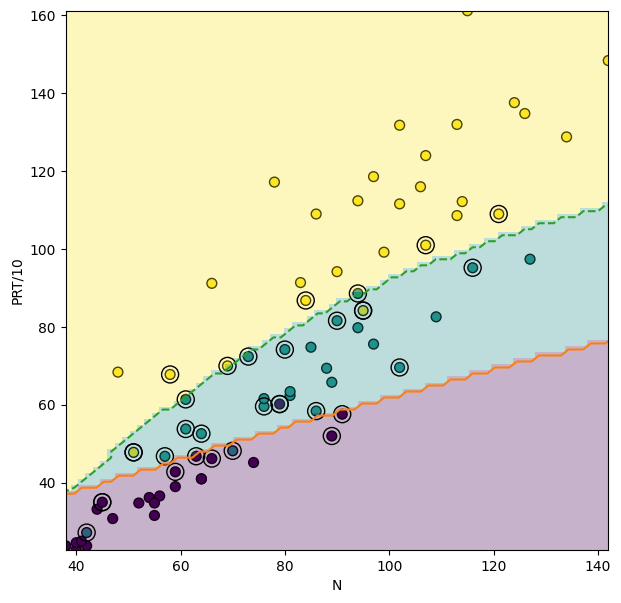

In [ ]:
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt

# Train SVM with RBF kernel using the best C and Gamma parameters found in the grid search for multi-class classification using One-vs-One strategy. The trained SVM model is then used to plot the decision boundaries and margins for the multi-class classification problem, as well as to visualize the support vectors that influence the position of the decision boundaries.
bestCP2 = CsP2[minErrorIx[0]][0]
bestGP2 = GsP2[minErrorIx[1]][0]
clf = OneVsOneClassifier(svm.SVC(kernel="rbf", C=2**bestCP2,gamma=2**bestGP2))
clf.fit(X_train, y_train)

y_predicted=clf.predict(X_test)
#Evaluate error
Hits=(np.where(y_predicted==y_test)[0]).shape[0]
Acc = Hits/y_test.shape[0]
#Compute error
error = (1-Acc)*100

print("Error (%) = "+str(error))

# Plotting settings
fig, ax = plt.subplots(figsize=(7, 7))
x_min, x_max, y_min, y_max = np.min(X_train[:,0]),np.max(X_train[:,0]),np.min(X_train[:,1]),np.max(X_train[:,1])
ax.set(xlim=(x_min, x_max), ylim=(y_min, y_max))

# Plot samples by color and add legend
scatter = ax.scatter(X_train[:, 0], X_train[:, 1], s=50, c=y_train, label=y_train, edgecolors="k")
plt.xlabel("N")
plt.ylabel("PRT/10")

# Plot decision boundary and margins
common_params = {"estimator": clf, "X": X, "ax": ax}
DecisionBoundaryDisplay.from_estimator(
    **common_params,
    response_method="predict",
    plot_method="pcolormesh",
    alpha=0.3,
)
DecisionBoundaryDisplay.from_estimator(
    **common_params,
    response_method="auto",
    plot_method="contour",
    levels=[-1, 0, 1],
    colors=["k", "k", "k"],
    linestyles=["--", "-", "--"],
)

# Plot bigger circles around samples that serve as support vectors 
# Since we are using a One-vs-One strategy for multi-class classification, there are multiple binary classifiers trained for each pair of classes. 
# Each binary classifier has its own set of support vectors, which can be accessed using the support_vectors_ attribute of the trained SVM model for each binary classifier. 
ax.scatter(
    clf.estimators_[0].support_vectors_[:, 0],
    clf.estimators_[0].support_vectors_[:, 1],
    s=150,
    facecolors="none",
    edgecolors="k",
    )
ax.scatter(
    clf.estimators_[1].support_vectors_[:, 0],
    clf.estimators_[1].support_vectors_[:, 1],
    s=150,
    facecolors="none",
    edgecolors="k",
    )
ax.scatter(
    clf.estimators_[2].support_vectors_[:, 0],
    clf.estimators_[2].support_vectors_[:, 1],
    s=150,
    facecolors="none",
    edgecolors="k",
    )

_ = plt.show()